# **Trabajo con mapas topográficos con datos EEG** 🧠🗺️

Un **mapa topográfico de EEG** es una representación visual que permite observar cómo se distribuyen espacialmente sobre el cuero cabelludo diferentes medidas de la actividad eléctrica cerebral, como la amplitud o la densidad de potencia del EEG, así como otras medidas de sincronización neuronal cortical local. Estas medidas pueden representarse mediante colores, a partir de los valores registrados en los electrodos o estimados en otras ubicaciones. Para generar una representación visual continua, se utilizan algoritmos de interpolación que estiman los valores entre los puntos de medición. Sin embargo, los resultados pueden variar según el método de interpolación utilizado, y la interpretación de la actividad de las fuentes corticales debe hacerse con precaución debido a los efectos de conducción de volumen de la cabeza (Babiloni et al., 2020; Beniczky y Schomer, 2020).

**⚠️ Advertencia**: Es importante considerar que la distribución topográfica del EEG puede variar según la referencia eléctrica utilizada, lo que puede modificar la apariencia de los mapas de potencia y afectar su interpretación. Además, la distribución de los potenciales en el cuero cabelludo no permite localizar directamente las fuentes neuronales subyacentes (Yao et al., 2019).

**-----------------**

Este es un tutorial para crear mapas topográficos de EEG a partir de datos específicos (ya sea almacenados en un archivo Excel o ingresandolos directamente aquí), utilizando Python y la biblioteca MNE. De forma predeterminada, los mapas se basan en el sistema de posicionamiento de electrodos 10–20 y con 19 canales; sin embargo, se pueden ajustar de acuerdo con las preferencias o necesidades. Esto permite visualizar la distribución espacial de diferentes métricas electrofisiológicas registradas en los canales EEG.

Aunque el tutorial está pensado principalmente para representar promedios de potencia absoluta por canal y banda de frecuencia, el mismo procedimiento puede aplicarse a otras métricas, como la frecuencia pico promedio, siempre que se utilicen los datos y las unidades correspondientes. Una vez organizados los datos en Excel, estos se cargan en el entorno de análisis para generar distintas visualizaciones y ajustar sus características gráficas según la métrica estudiada.

**Selección del mapa de colores:** Se recomienda utilizar mapas secuenciales, como `viridis`, para representar magnitudes no negativas, y mapas divergentes, como `RdBu_r`, para visualizar diferencias o correlaciones con valores positivos y negativos, manteniendo escalas de color comparables cuando se contrasten mapas.

*Nota:* Este cuaderno fue desarrollado y probado con `Python 3.12.0`


# 0. Configuración inicial


Si no tienes instaladas las siguientes bibliotecas en las versiones especificadas, ejecuta el siguiente bloque en un entorno virtual nuevo para evitar posibles conflictos con otras bibliotecas instaladas.

In [ ]:
%pip install mne==1.5.1 numpy==2.0.2 pandas==2.2.3 matplotlib==3.11.2 openpyxl==3.1.5

Se cargan las librerias

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mne

# 1.Preparación

Definimos los 19 canales EEG y asignamos sus posiciones espaciales según el sistema estándar 10–20. Esto permite a MNE ubicar cada canal correctamente en el mapa sin necesidad de cargar un archivo EEG previo. Por defecto, utilizamos el montaje estándar 10–20 con 19 canales, pero es posible modificar la lista para incorporar otros canales o utilizar otro montaje compatible con MNE. Los nombres y el orden de los canales deben coincidir con los datos que se representarán en los topomapas.

In [4]:
# Define los canales EEG; por defecto, se utiliza el montaje 10–20 de 19 canales
ch_names = [
    "Fp1", "Fp2", "F3", "F4", "C3", "C4", "P3", "P4", "O1", "O2",
    "F7", "F8", "T3", "T4", "T5", "T6", "Fz", "Cz", "Pz"
]

# Selecciona el montaje que corresponda a los canales utilizados
montaje = "standard_1020"

# Crea la estructura de información de los canales EEG
info = mne.create_info(
    ch_names=ch_names,
    sfreq=250,
    ch_types="eeg"
)

# Asigna las posiciones espaciales del montaje seleccionado
info.set_montage(montaje)

<Info | 8 non-empty values
 bads: []
 ch_names: Fp1, Fp2, F3, F4, C3, C4, P3, P4, O1, O2, F7, F8, T3, T4, T5, ...
 chs: 19 EEG
 custom_ref_applied: False
 dig: 22 items (3 Cardinal, 19 EEG)
 highpass: 0.0 Hz
 lowpass: 125.0 Hz
 meas_date: unspecified
 nchan: 19
 projs: []
 sfreq: 250.0 Hz
>

Para cambiar el montaje, basta con modificar montaje por otro compatible con MNE, por ejemplo `"standard_1005"` (compatible con la versión que estamos usando de MNE). Si se agregan canales que no existen en el montaje estándar elegido, será necesario proporcionar sus posiciones mediante un montaje personalizado.

## 2. De los datos al objeto en Python

Para generar los mapas topográficos, necesitas definir el objetivo de la visualización, la unidad de medida, las etiquetas de las bandas de frecuencia o métricas y sus valores para cada canal EEG. Puedes preparar esta información de dos maneras: **cargando un archivo Excel** o **ingresando los datos directamente en el cuaderno**.

- **Ruta 1. Desde Excel:** organiza previamente los datos en el archivo `EEG_datos.xlsx` y cárgalos en Python. Esta opción facilita la edición y organización de los datos antes de generar los mapas.

*Nota:* por defecto, el código busca el archivo `EEG_datos.xlsx` en el directorio de trabajo actual de Python. Si el archivo se encuentra en la misma carpeta que el cuaderno de Jupyter y esta coincide con el directorio de trabajo, no necesitas especificar una ruta adicional. De lo contrario, indica la ruta relativa o absoluta al archivo. Por ejemplo:

`metadatos = pd.read_excel("datos/EEG_datos.xlsx", header=None)`

En este ejemplo, el archivo se encuentra en una subcarpeta llamada datos.

- **Ruta 2. Directamente en Python:** define los metadatos, las etiquetas y los valores por canal en el propio cuaderno, sin necesidad de utilizar un archivo externo.

Ambas rutas permiten preparar los datos para generar los mapas topográficos. Elige la que mejor se adapte a tu flujo de trabajo y sigue únicamente las instrucciones correspondientes a esa opción. 

**Importante:** independientemente de la ruta elegida, los nombres de los canales y su orden deben coincidir exactamente con los definidos previamente en el montaje EEG (`ch_names`). Además, cada banda o métrica debe contener un valor por canal. Esto garantiza que los valores se asignen a las posiciones correctas en los mapas. 

### Ruta 1 - Excel

In [7]:
# Lee los metadatos de la primera fila del Excel
metadatos = pd.read_excel("EEG_datos.xlsx", header=None)

# Guarda el objetivo y la unidad de medida indicados en el Excel
objetivo = str(metadatos.iloc[0, 1])
unit_label = str(metadatos.iloc[0, 3])

# Carga los datos usando la tercera fila como encabezado de los canales
df = pd.read_excel("EEG_datos.xlsx", header=2, index_col=0)

# Elimina las columnas vacías que pueda contener el archivo
df = df.dropna(axis=1, how="all")

# Guarda las etiquetas de las bandas o métricas
labels = df.index.tolist()

# Convierte los valores con coma decimal a formato numérico, si es necesario
df = df.apply(lambda col: pd.to_numeric(
    col.astype(str).str.replace(",", ".", regex=False),
    errors="raise"
))

# Comprueba que los canales coincidan con la configuración del montaje
if list(df.columns) != ch_names:
    raise ValueError(
        "Las columnas del Excel deben coincidir exactamente y en el mismo orden "
        "con ch_names. Revisa los nombres y la disposición de los canales."
    )

# Convierte los datos a una matriz numérica
data3 = df.to_numpy(dtype=float)

# Comprueba que cada banda tenga un valor por canal
if data3.shape != (len(labels), len(ch_names)):
    raise ValueError("Las dimensiones de los datos no coinciden con las etiquetas y los canales.")

# Muestra la configuración de los datos
print("Objetivo:", objetivo)
print("Unidad de medida:", unit_label)
print("Bandas o métricas:", labels)
print("Canales:", len(ch_names))
print("Dimensiones de data3:", data3.shape)

Objetivo: Potencia absoluta promedio
Unidad de medida: µV²
Bandas o métricas: ['Theta', 'Delta', 'Alfa', 'Beta']
Canales: 19
Dimensiones de data3: (4, 19)


### Ruta 2: Directamente en Python

Si prefieres no utilizar un archivo Excel, puedes introducir los datos directamente en el cuaderno. Define el objetivo de la visualización, la unidad de medida, las etiquetas de las bandas o métricas y sus valores por canal EEG. Puedes agregar o quitar bandas y canales según tus necesidades, siempre que cada fila de datos contenga un valor por canal y que el orden coincida con `ch_names`, definido en el apartado del montaje. Esta alternativa permite trabajar directamente en Python, mientras que Excel facilita la organización previa de los datos. Ambas opciones son válidas y puedes elegir la que mejor se adapte a tu flujo de trabajo.

In [9]:
# Define el objetivo y la unidad de medida
objetivo = "Potencia absoluta promedio"
unit_label = "µV²"

# Define las etiquetas de las bandas o métricas
labels = ["Theta", "Delta", "Alfa", "Beta"]

# Introduce los valores por canal, en el mismo orden de ch_names
data3 = np.array([
    [10.42, 13.18, 14.76, 16.32, 18.54, 21.07, 22.63, 19.85, 25.31, 23.46, 9.17, 7.84, 8.93, 6.72, 14.28, 12.65, 16.91, 18.73, 22.14],
    [14.63, 12.85, 17.42, 13.96, 20.31, 18.74, 23.16, 21.52, 27.83, 24.19, 9.52, 8.67, 7.91, 8.34, 16.42, 13.78, 19.24, 17.86, 21.63],
    [11.76, 10.94, 13.82, 16.57, 17.29, 19.46, 20.83, 22.17, 24.68, 21.35, 8.73, 9.26, 7.64, 8.15, 13.97, 15.31, 18.42, 20.16, 22.87],
    [13.24, 12.67, 16.18, 14.83, 21.42, 19.68, 22.35, 18.97, 28.14, 25.72, 7.96, 8.54, 9.13, 7.28, 16.75, 14.92, 17.63, 21.48, 24.36]
], dtype=float)

# Comprueba que las dimensiones coincidan con las etiquetas y los canales
assert data3.shape == (len(labels), len(ch_names)), (
    "Debe haber una fila por etiqueta y una columna por canal EEG."
)

# Muestra la configuración de los datos
print("Objetivo:", objetivo)
print("Unidad de medida:", unit_label)
print("Bandas o métricas:", labels)
print("Canales:", len(ch_names))
print("Dimensiones de data3:", data3.shape)

Objetivo: Potencia absoluta promedio
Unidad de medida: µV²
Bandas o métricas: ['Theta', 'Delta', 'Alfa', 'Beta']
Canales: 19
Dimensiones de data3: (4, 19)


# 3. Graficamos en un mapa topográfico

Tenemos diversas opciones para graficar los datos de acuerdo a nuestras necesidades. Esto tambien depende de si tenemos varias bandas por graficas (opciones grupales) o si queremos graficas una (opciones individuales).

**Escala de colores:** Para facilitar la comparación entre mapas, se establecen límites comunes (`vmin` y `vmax`), calculados a partir de los valores de las métricas representadas. Así, un mismo color corresponde al mismo valor en todos los mapas. Cuando se visualiza una sola banda, pueden utilizarse límites automáticos o conservarse los mismos límites para compararla con otras figuras. Si los datos incluyen valores negativos, se recomienda ajustar los límites para incluir ambos signos y considerar una paleta divergente centrada en cero, siempre que este sea un punto de referencia significativo. La escala debe elegirse según los datos y el objetivo de la visualización.

## Opciones grupales
**Advertencia**: estos códigos no funcionaran si tu `data` tiene solo una banda representada.

### Forma con bucles - vertical 

Unidad de medida: µV²


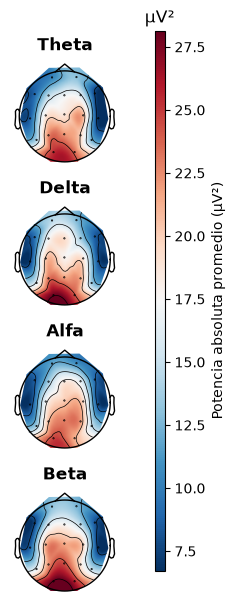

In [8]:
# Usa la unidad de medida definida previamente, ya sea desde Excel o manualmente
print("Unidad de medida:", unit_label)

# Una única escala para todas las métricas
vmin = np.min(data3)
vmax = np.max(data3)

# Crea la figura y un eje por cada conjunto de datos.
# squeeze=False evita errores cuando data3 contiene un solo elemento.
fig, ax = plt.subplots(len(data3), figsize=(2, 6), squeeze=False)

# Genera un mapa topográfico para cada conjunto de datos.
for i in range(len(data3)):
    im, cm = mne.viz.plot_topomap(
        data3[i],  # Valores que se representarán en el mapa.
        info,  # Información y posiciones de los electrodos.
        sphere=(0.00, 0.02, 0.03, 0.112),  # Define la esfera de la cabeza.
        cmap='RdBu_r',  # Escala divergente de azul a rojo; también puedes usar 'viridis', una escala secuencial.
        vlim=(vmin, vmax),
        extrapolate="local",  # Limita la extrapolación a zonas cercanas a los sensores.
        axes=ax[i, 0],  # Selecciona el eje donde se dibujará el mapa.
        show=False  # Evita mostrar la figura antes de terminar su configuración.
    )

# Ajusta los espacios entre los mapas.
fig.tight_layout(pad=2)

# Asigna a cada mapa el nombre correspondiente de la lista labels.
for i in range(len(labels)):
    ax[i, 0].set_title(labels[i], fontweight='bold')

# Define la posición y las dimensiones de la barra de color.
ax_x_start = 0.95   # Posición horizontal desde la izquierda.
ax_x_width = 0.05   # Ancho de la barra.
ax_y_start = 0.1    # Posición vertical desde abajo.
ax_y_height = 0.9   # Altura de la barra.

# Crea un eje independiente para colocar la barra de color.
cbar_ax = fig.add_axes([
    ax_x_start, ax_y_start, ax_x_width, ax_y_height
])

# Añade la barra de color usando el último mapa generado.
clb = fig.colorbar(im, cax=cbar_ax)

# Coloca la unidad de medida encima de la barra de color.
clb.ax.set_title(unit_label)

# Identifica la magnitud representada y su unidad
clb.set_label(f"{objetivo} ({unit_label})")

# Muestra la figura final.
plt.show()


### Forma larga - horizontal

Unidad de medida: µV²


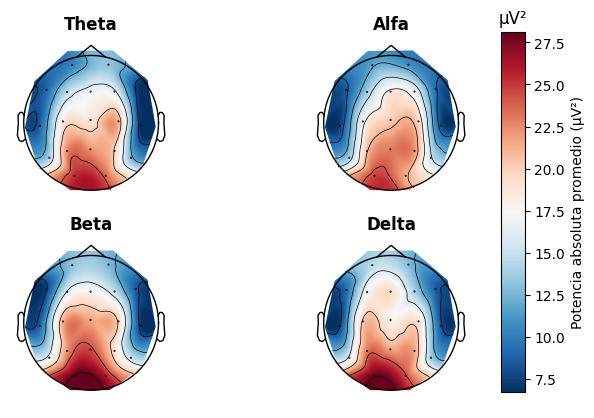

In [13]:
# Usa la unidad de medida definida previamente, ya sea desde Excel o manualmente
print("Unidad de medida:", unit_label)

# Una única escala para todas las métricas
vmin = np.min(data3)
vmax = np.max(data3)

# Crea una figura con cuatro mapas en una cuadrícula de 2 filas y 2 columnas.
fig, ax = plt.subplots(2, 2, figsize=(6, 4))

# Ajusta los espacios entre los mapas.
fig.tight_layout(pad=0)

# Añade el título y genera el primer mapa en la posición superior izquierda.
ax[0,0].set_title(labels[0], fontweight='bold')
im,cm = mne.viz.plot_topomap(data3[0], info, sphere=(0.00, 0.02, 0.03, 0.112), cmap='RdBu_r', vlim=(vmin, vmax), extrapolate="local", axes=ax[0,0], show=False)

# Añade el título del cuarto mapa y lo genera en la posición inferior izquierda.
ax[1,0].set_title(labels[3], fontweight='bold')
im,cm = mne.viz.plot_topomap(data3[3], info, sphere=(0.00, 0.02, 0.03, 0.112), cmap='RdBu_r', vlim=(vmin, vmax), extrapolate="local", axes=ax[1,0], show=False)

# Añade el título y genera el tercer mapa en la posición superior derecha.
ax[0,1].set_title(labels[2], fontweight='bold')
im,cm = mne.viz.plot_topomap(data3[2], info, sphere=(0.00, 0.02, 0.03, 0.112), cmap='RdBu_r', vlim=(vmin, vmax), extrapolate="local", axes=ax[0,1], show=False)

# Añade el título del segundo mapa y lo genera en la posición inferior derecha.
ax[1,1].set_title(labels[1], fontweight='bold')
im,cm = mne.viz.plot_topomap(data3[1], info, sphere=(0.00, 0.02, 0.03, 0.112), cmap='RdBu_r', vlim=(vmin, vmax), extrapolate="local", axes=ax[1,1], show=False)

# Define la posición y las dimensiones de la barra de color.
ax_x_start = 0.95
ax_x_width = 0.04
ax_y_start = 0.1
ax_y_height = 0.9

# Crea un eje independiente para colocar la barra de color.
cbar_ax = fig.add_axes([ax_x_start, ax_y_start, ax_x_width, ax_y_height])

# Añade la barra de color utilizando el último mapa generado.
clb = fig.colorbar(im, cax=cbar_ax)

# Muestra la unidad de medida encima de la barra de color.
clb.ax.set_title(unit_label)

# Identifica la magnitud representada y su unidad
clb.set_label(f"{objetivo} ({unit_label})")

# Muestra la figura final.
plt.show()


### Forma larga con dos imagenes y usando *"viridis"*

Unidad de medida: µV²


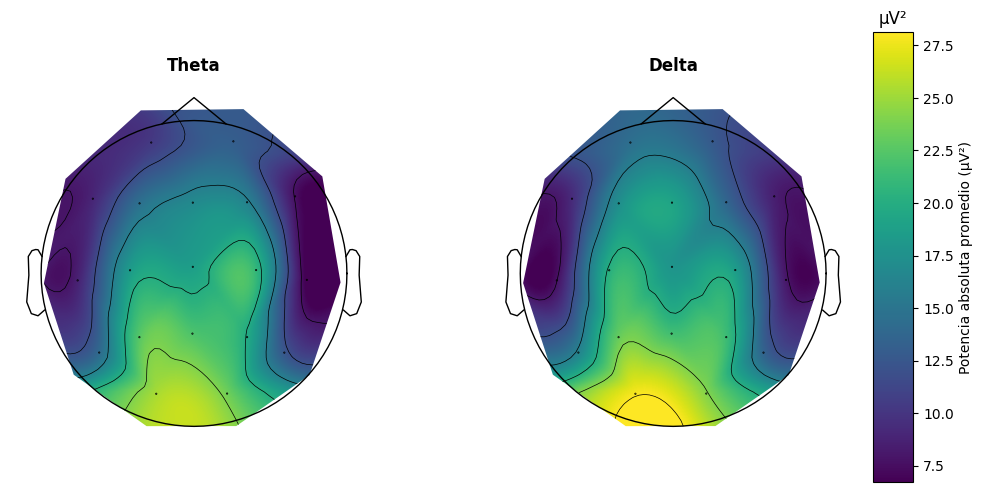

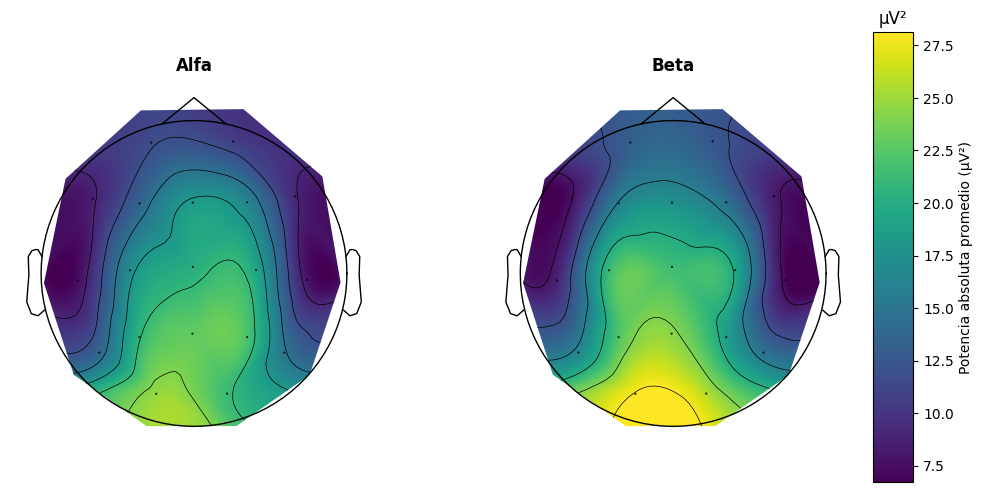

In [18]:
# Usa la unidad de medida definida previamente, ya sea desde Excel o manualmente
print("Unidad de medida:", unit_label)

# Una única escala para todas las métricas
vmin = np.min(data3)
vmax = np.max(data3)

# Figura 1: representa los dos primeros mapas topográficos.
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
fig.tight_layout(pad=3)

# Asigna el título y genera el primer mapa.
ax[0].set_title(labels[0], fontweight='bold')
im, cm = mne.viz.plot_topomap(
    data3[0], info,
    sphere=(0.00, 0.02, 0.03, 0.112),
    cmap='viridis',  # Escala divergente azul-rojo; también puedes usar 'viridis'.
    vlim=(vmin, vmax),
    extrapolate="local",
    axes=ax[0],
    show=False
)

# Asigna el título y genera el segundo mapa.
ax[1].set_title(labels[1], fontweight='bold')
im, cm = mne.viz.plot_topomap(
    data3[1], info,
    sphere=(0.00, 0.02, 0.03, 0.112),
    cmap='viridis',
    vlim=(vmin, vmax),
    extrapolate="local",
    axes=ax[1],
    show=False
)

# Define la posición y las dimensiones de la barra de color.
ax_x_start = 0.95
ax_x_width = 0.04
ax_y_start = 0.1
ax_y_height = 0.9

# Crea la barra de color y añade la unidad de medida.
cbar_ax = fig.add_axes([ax_x_start, ax_y_start, ax_x_width, ax_y_height])
clb = fig.colorbar(im, cax=cbar_ax)
clb.ax.set_title(unit_label)
# Identifica la magnitud representada y su unidad
clb.set_label(f"{objetivo} ({unit_label})")

# Muestra la primera figura.
plt.show()


# Figura 2: representa los dos mapas topográficos siguientes.
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
fig.tight_layout(pad=3)

# Asigna el título y genera el tercer mapa.
ax[0].set_title(labels[2], fontweight='bold')
im, cm = mne.viz.plot_topomap(
    data3[2], info,
    sphere=(0.00, 0.02, 0.03, 0.112),
    cmap='viridis',
    vlim=(vmin, vmax),
    extrapolate="local",
    axes=ax[0],
    show=False
)

# Asigna el título y genera el cuarto mapa.
ax[1].set_title(labels[3], fontweight='bold')
im, cm = mne.viz.plot_topomap(
    data3[3], info,
    sphere=(0.00, 0.02, 0.03, 0.112),
    cmap='viridis',
    vlim=(vmin, vmax),
    extrapolate="local",
    axes=ax[1],
    show=False
)

# Define la posición y las dimensiones de la barra de color.
ax_x_start = 0.95
ax_x_width = 0.04
ax_y_start = 0.1
ax_y_height = 0.9

# Crea la barra de color y añade la unidad de medida.
cbar_ax = fig.add_axes([ax_x_start, ax_y_start, ax_x_width, ax_y_height])
clb = fig.colorbar(im, cax=cbar_ax)
clb.ax.set_title(unit_label)
# Identifica la magnitud representada y su unidad
clb.set_label(f"{objetivo} ({unit_label})")

# Muestra la segunda figura.
plt.show()


# Opciones individuales

Si solo tienes una banda para graficar, esta sección es ideal. Ten en cuenta que si estas graficando varias bandas, en esta sección puedes graficar individualmente cada una de ellas.

*En el caso de que tengas varias bandas, debes saber ubicarlas*

In [7]:
#Ten en cuenta la ubicación de los labels
print(labels)
# Muestra la posición (índice) y el nombre de cada label.
for i, label in enumerate(labels):
    print(f"Posición {i}: {label}")

['Theta', 'Delta', 'Alfa', 'Beta']
Posición 0: Theta
Posición 1: Delta
Posición 2: Alfa
Posición 3: Beta


Lo anterior no aplica si solo tienes una.

### Forma1

Objetivo: Potencia absoluta promedio


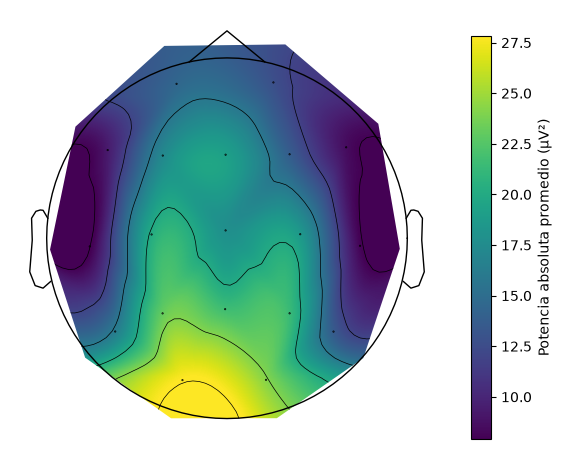

In [9]:
# Índice del dato que deseas representar.
i = 1

# Extrae los valores numéricos del dato seleccionado.
data = np.asarray(data3[i], dtype=float)

# Obtiene automáticamente el nombre correspondiente al dato.
# Por ejemplo: "Delta".
label_actual = labels[i]

# Calcula los valores mínimo y máximo para ajustar la escala de colores.
vmin = np.min(data)
vmax = np.max(data)

# Crea la figura y el eje donde se dibujará el mapa topográfico.
fig, ax = plt.subplots(figsize=(7, 6))

# Genera el mapa topográfico con los valores de poder absoluto promedio.
im, _ = mne.viz.plot_topomap(
    data,
    info,
    sphere=(0.00, 0.02, 0.03, 0.112),
    cmap="viridis", # cmap: "viridis" usa una escala secuencial de colores; "RdBu_r" usa una escala divergente de azul a rojo para resaltar contrastes.
    vlim=(vmin, vmax),
    extrapolate="local",
    axes=ax,
    show=False
)

# Utiliza el objetivo definido previamente, ya sea desde Excel o manualmente
print("Objetivo:", objetivo)

# Si deseas asignar el título según el objetivo y la banda seleccionada, descomenta esta sección.
#ax.set_title(
#    f"{objetivo} – {label_actual}",
#    fontweight="bold"
#)

# Añade la barra de color al mapa
cbar = fig.colorbar(im, ax=ax, shrink=0.8)

# Identifica la magnitud representada y su unidad
cbar.set_label(f"{objetivo} ({unit_label})")

# Muestra el mapa topográfico terminado
plt.show()

### Forma 1 con *RdBu_r* + visualización de los electrodos con sus etiquetas

Objetivo: Potencia absoluta promedio


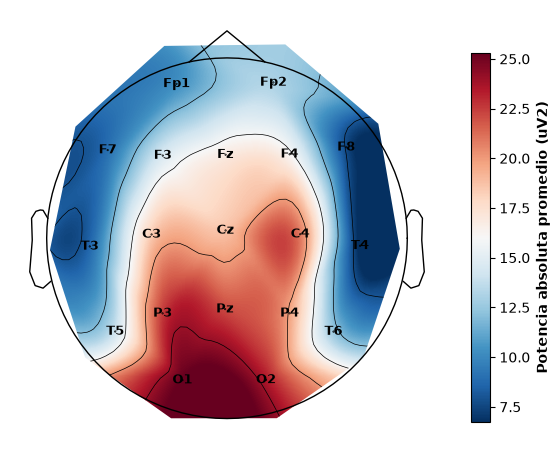

In [9]:
# Índice del dato que deseas representar.
i = 0

# Extrae los valores numéricos del dato seleccionado.
data = np.asarray(data3[i], dtype=float)

# Obtiene automáticamente el nombre correspondiente al dato.
label_actual = labels[i]

# Calcula los valores mínimo y máximo para ajustar la escala de colores.
vmin = np.min(data)
vmax = np.max(data)

# Crea la figura y el eje del mapa topográfico.
fig, ax = plt.subplots(figsize=(7, 6))

# Genera el mapa topográfico del poder absoluto promedio.
im, _ = mne.viz.plot_topomap(
    data,
    info,
    sphere=(0.00, 0.02, 0.03, 0.112),
    cmap="RdBu_r",  # esta vez usamos "RdBu_r"
    vlim=(vmin, vmax),
    extrapolate="local",
    axes=ax,
    show=False,
    sensors=True,  # Muestra la ubicación de los sensores.
    names=info["ch_names"],  # Añade los nombres de los canales.
    contours=6  # Dibuja seis niveles de contorno.
)

# Configura las etiquetas de los electrodos en negrita.
for text in ax.texts:
    text.set_fontweight("bold")
    text.set_fontsize(9)

# Utiliza el objetivo definido previamente, ya sea desde Excel o manualmente
print("Objetivo:", objetivo)

# Si deseas asignar el título según el objetivo y la banda seleccionada, descomenta esta sección.
#ax.set_title(
#    f"{objetivo} – {label_actual}",
#    fontweight="bold"
#)

# Crea la barra de color e identifica la magnitud representada y su unidad
cbar = fig.colorbar(im, ax=ax, shrink=0.8)
cbar.set_label(
    f"{objetivo} ({unit_label})",
    fontweight="bold"
)

# Muestra el mapa topográfico final
plt.show()

### Forma 2

Unidad de medida: µV²


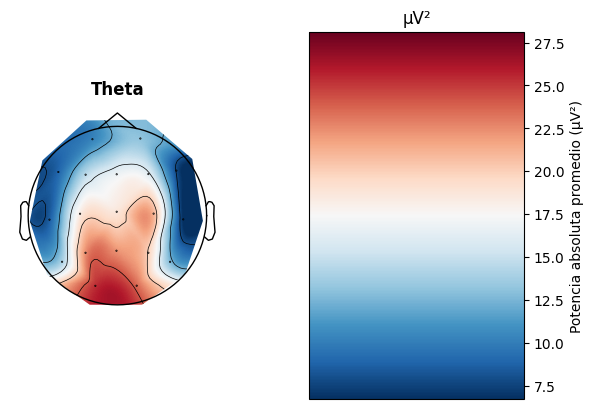

In [15]:
# Usa la unidad de medida definida previamente, ya sea desde Excel o manualmente
print("Unidad de medida:", unit_label)

# Calcula los valores mínimo y máximo para ajustar la escala de colores.
vmin = np.min(data3)
vmax = np.max(data3)

# Crea una figura con dos espacios: uno para el mapa y otro para la barra de color.
fig, ax = plt.subplots(1, 2)

# Ajusta los espacios entre los elementos de la figura.
fig.tight_layout(pad=3)

# Añade el título al mapa topográfico.
ax[0].set_title(labels[0], fontweight='bold')

# Genera el mapa topográfico con los datos seleccionados.
im1, cm = mne.viz.plot_topomap(
    data3[0], info,
    sphere=(0.00, 0.02, 0.03, 0.112),
    cmap='RdBu_r',
    vlim=(vmin, vmax),
    extrapolate="local",
    axes=ax[0],
    show=False
)

# Añade la barra de color en el segundo espacio de la figura.
clb = fig.colorbar(im1, cax=ax[1])

# Muestra la unidad de medida encima de la barra de color.
clb.ax.set_title(unit_label)
clb.set_label(
    f"{objetivo} ({unit_label})"
)

# Muestra la figura final.
plt.show()

### 2 graficas individuales con barra

Unidad de medida: µV²


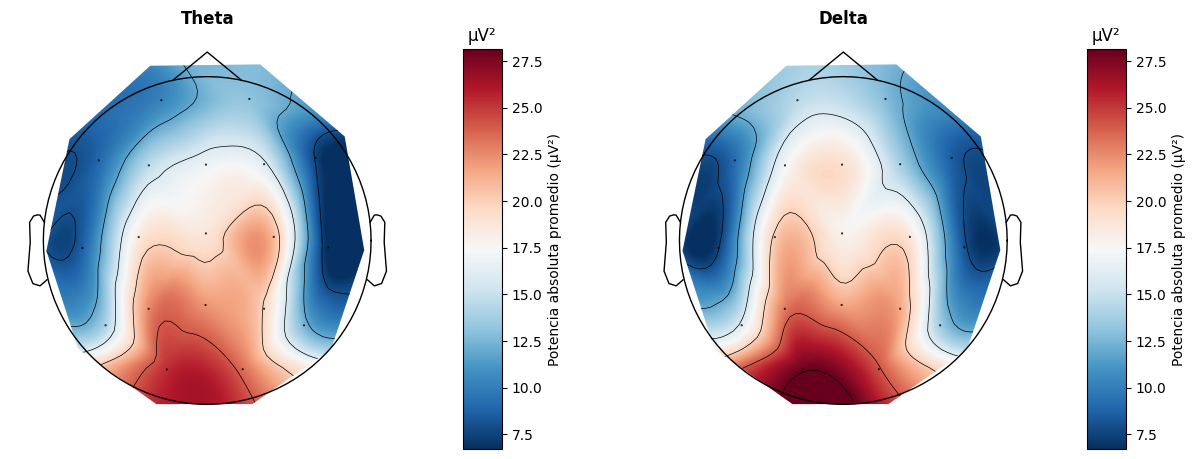

In [16]:
# Usa la unidad de medida definida previamente, ya sea desde Excel o manualmente
print("Unidad de medida:", unit_label)

# Calcula los valores mínimo y máximo para ajustar la escala de colores.
vmin = np.min(data3)
vmax = np.max(data3)

# Crea una figura con dos mapas topográficos en paralelo.
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

# Ajusta los espacios entre los elementos de la figura.
fig.tight_layout(pad=2)

# Añade el título del primer mapa.
ax[0].set_title(labels[0], fontweight='bold')

# Genera el primer mapa topográfico.
im1, cm = mne.viz.plot_topomap(
    data3[0], info,
    sphere=(0.00, 0.02, 0.03, 0.112),
    cmap='RdBu_r',
    vlim=(vmin, vmax),
    extrapolate="local",
    axes=ax[0],
    show=False
)

# Define la posición y las dimensiones de la primera barra de color.
ax_x_start1 = 0.46
ax_x_width1 = 0.03
ax_y_start1 = 0.1
ax_y_height1 = 0.8

# Crea la primera barra de color y añade su unidad de medida.
cbar_ax1 = fig.add_axes([ax_x_start1, ax_y_start1, ax_x_width1, ax_y_height1])
clb1 = fig.colorbar(im1, cax=cbar_ax1)
clb1.ax.set_title(unit_label)
clb1.set_label(
    f"{objetivo} ({unit_label})"
)

# Añade el título del segundo mapa.
ax[1].set_title(labels[1], fontweight='bold')

# Genera el segundo mapa topográfico.
im2, cm = mne.viz.plot_topomap(
    data3[1], info,
    sphere=(0.00, 0.02, 0.03, 0.112),
    cmap='RdBu_r',
    vlim=(vmin, vmax),
    extrapolate="local",
    axes=ax[1],
    show=False
)

# Define la posición y las dimensiones de la segunda barra de color.
ax_x_start2 = 0.94
ax_x_width2 = 0.03
ax_y_start2 = 0.1
ax_y_height2 = 0.8

# Crea la segunda barra de color y añade su unidad de medida.
cbar_ax2 = fig.add_axes([ax_x_start2, ax_y_start2, ax_x_width2, ax_y_height2])
clb2 = fig.colorbar(im2, cax=cbar_ax2)
clb2.ax.set_title(unit_label)
clb2.set_label(
    f"{objetivo} ({unit_label})"
)

# Para guardar la figura en alta resolución, descomenta la siguiente línea.
# plt.savefig('my_plot.pdf', dpi=300, bbox_inches='tight')

# Muestra la figura final.
plt.show()

## Para finalizar

En este cuaderno se exploraron diferentes formas de representar métricas de EEG mediante mapas topográficos con MNE-Python, partiendo de datos organizados por canal. A través de las distintas opciones de visualización, vimos cómo adaptar la disposición de los mapas, las escalas de color y las etiquetas según el propósito de cada figura.

Recuerda que la interpretación de un topomapa depende de la métrica representada, sus unidades, el montaje de electrodos y los parámetros de visualización utilizados. Los mapas facilitan la exploración de patrones espaciales, pero deben interpretarse en el contexto de los datos y del diseño del estudio. 

Experimenta con tus propios datos, prueba las diferentes configuraciones y elige la representación que mejor responda a tu pregunta de investigación. Este cuaderno es un punto de partida para seguir explorando las posibilidades de visualización de EEG con Python y MNE.

# Referencias

Babiloni, C., Barry, R. J., Başar, E., Blinowska, K. J., Cichocki, A., Drinkenburg, W. H. I. M., Klimesch, W., Knight, R. T., Lopes da Silva, F., Nunez, P., Oostenveld, R., Jeong, J., Pascual-Marqui, R., Valdes-Sosa, P. y Hallett, M. (2020). International Federation of Clinical Neurophysiology (IFCN) - EEG research workgroup: Recommendations on frequency and topographic analysis of resting state EEG rhythms. Part 1: Applications in clinical research studies. *Clinical neurophysiology : official journal of the International Federation of Clinical Neurophysiology, 131*(1), 285–307. https://doi.org/10.1016/j.clinph.2019.06.234

Beniczky, S. y Schomer, D. L. (2020). Electroencephalography: basic biophysical and technological aspects important for clinical applications. *Epileptic disorders : international epilepsy journal with videotape, 22*(6), 697–715. https://doi.org/10.1684/epd.2020.1217

Yao, D., Qin, Y., Hu, S., Dong, L., Bringas Vega, M. L. y Valdés Sosa, P. A. (2019). Which Reference Should We Use for EEG and ERP practice?. *Brain topography, 32*(4), 530–549. https://doi.org/10.1007/s10548-019-00707-x

